In [636]:
import numpy as np
from skimage.measure import label
from skimage.filters import gaussian, sobel
from skimage.morphology import binary_closing, disk, binary_dilation, area_closing, area_opening
import skimage.feature as skf
import h5py as h5
import matplotlib.pyplot as plt
import scipy.ndimage as ndi

In [637]:
file = "/Users/bjha/Data/AFTIDL/aft304/AFT304/2014/01/AFTmap_20140101_0000.h5"
with h5.File(file) as fl:
    bmap = fl["maps/aftmap"][()]

In [638]:
def plotmap(image, ax=None, **kwargs):
    if ax is None:
        fig, ax=plt.subplots(1,1, figsize=(10,6))
    ax.imshow(image, origin="lower", cmap="gray", **kwargs)
    return ax

def get_mask(image, rsmooth=5):
    imsmooth = gaussian(image, rsmooth)
    return imsmooth

<Figure size 1000x500 with 0 Axes>

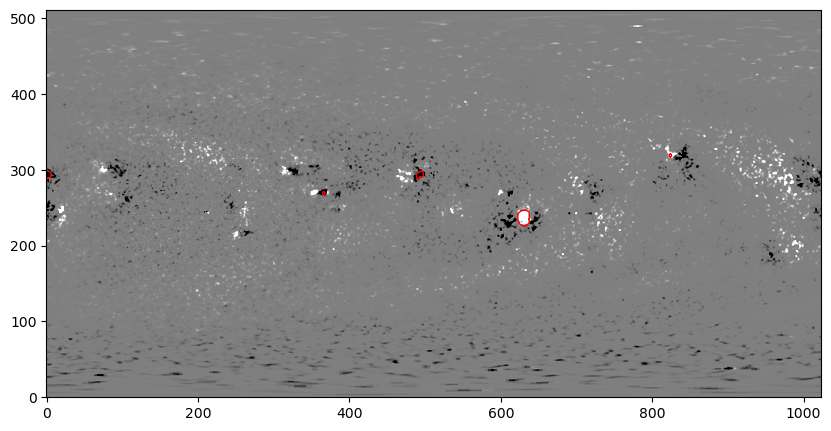

In [593]:
import cv2 as cv
file = "/Users/bjha/Data/AFTIDL/aft304/AFT304/2010/06/AFTmap_20100602_0000.h5"
file = "/Users/bjha/Data/AFTIDL/aft304/AFT304/2016/06/AFTmap_20160601_0000.h5"
with h5.File(file) as fl:
    bmap = fl["maps/aftmap"][()]
mask = get_mask(bmap, rsmooth=4)
pixelv = np.float32(np.abs(mask).reshape((-1,2)))
criteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 100, 1)
retval, labels, centers = cv.kmeans(pixelv, 3, None, criteria, 10, cv.KMEANS_RANDOM_CENTERS) 

centers = np.uint8(centers)
segmented_data = centers[labels.flatten()]
segmented_image = segmented_data.reshape((mask.shape))
mask = np.where(segmented_image == np.unique(centers.flatten())[-1], 1, 0)
plt.figure(figsize=(10,5))
ax = plotmap(bmap, vmax=100, vmin=-100)
mask = binary_closing(mask, disk(15))
mask = binary_dilation(mask, disk(1))
ax.contour(mask, linewidths=1, colors="red")
# plt.imshow(segmented_image)

## Cany

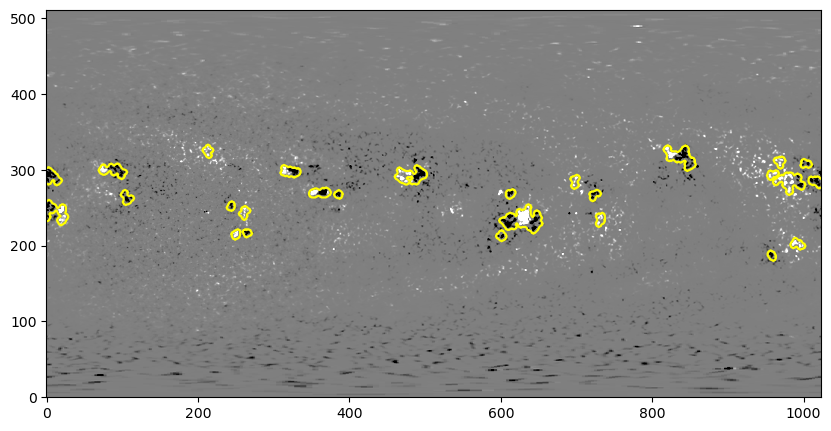

In [598]:
import cv2 as cv
file = "/Users/bjha/Data/AFTIDL/aft304/AFT304/2010/06/AFTmap_20100602_0000.h5"
# file = "/Users/bjha/Data/AFTIDL/aft304/AFT304/2014/01/AFTmap_20140101_0000.h5"
file = "/Users/bjha/Data/AFTIDL/aft304/AFT304/2016/06/AFTmap_20160601_0000.h5"
with h5.File(file) as fl:
    bmap = fl["maps/aftmap"][()]
mask = np.where(np.abs(bmap) >100, 1,0)
maskc = binary_closing(mask, disk(4))
maskc = area_opening(maskc, 5)
maskc = ndi.binary_fill_holes(maskc)
maskc = area_opening(maskc, 20)
maskc = binary_closing(maskc, disk(4))
maskc = binary_dilation(maskc, disk(3))

plt.figure(figsize=(10,6))
plt.imshow(bmap, origin="lower", vmin=-100, vmax=100, cmap="gray")
plt.contour(maskc, colors="yellow")

## Sklearn

In [586]:
from sklearn.cluster import DBSCAN
file = "/Users/bjha/Data/AFTIDL/aft304/AFT304/2010/06/AFTmap_20100602_0000.h5"
file = "/Users/bjha/Data/AFTIDL/aft304/AFT304/2014/01/AFTmap_20140101_0000.h5"
with h5.File(file) as fl:
    bmap = fl["maps/aftmap"][()]

mask = np.where(np.abs(bmap) >100, 1, 0)
maskc = binary_closing(mask, disk(4))
ind = np.where(mask == 1)
y,x = ind[0], ind[1]
xx = np.vstack([y, x]).T
clustering = DBSCAN(eps=20, min_samples=10).fit(xx)

In [587]:
clustering.labels_

array([-1, -1, -1, ..., -1, -1, -1])

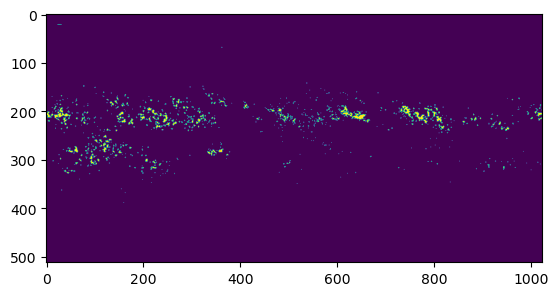

In [580]:
plt.imshow(mask)

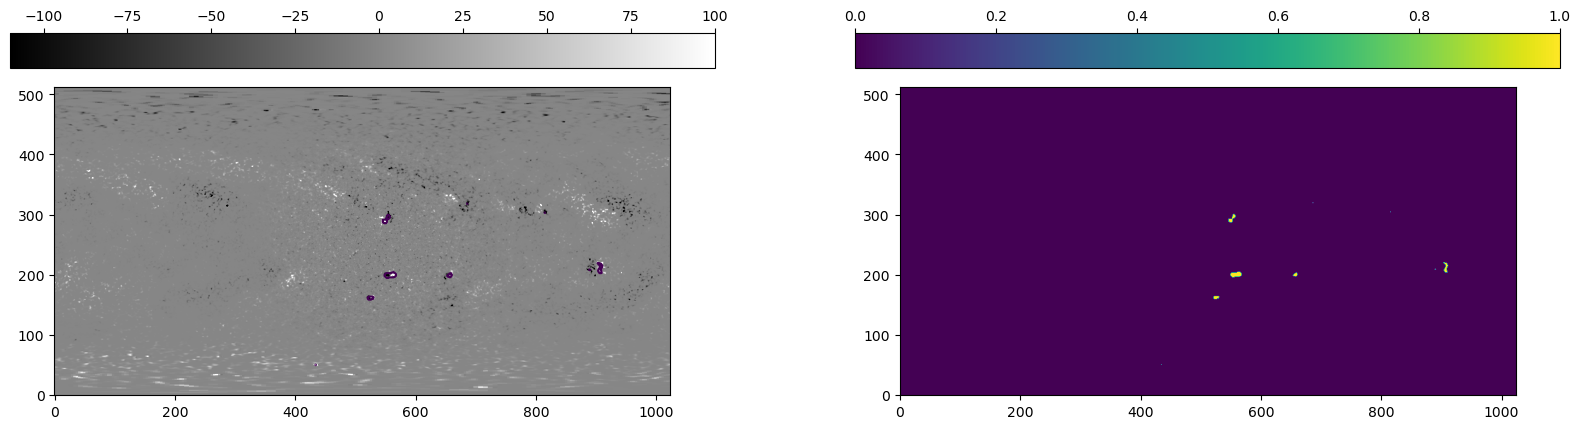

In [711]:
from skimage.feature import match_descriptors, plot_matches, SIFT
import skimage.filters as skfilter
file = "/Users/bjha/Data/AFTIDL/aft304/AFT304/2010/06/AFTmap_20100602_0000.h5"
# file = "/Users/bjha/Data/AFTIDL/aft304/AFT304/2014/01/AFTmap_20140101_0000.h5"
with h5.File(file) as fl:
    bmap = fl["maps/aftmap"][()]
imsmooth = get_mask(np.abs(bmap), rsmooth=3)

im = skfilter.laplace(imsmooth,10, mask=np.where(imsmooth > 40, 1,0))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20,5))
cm1=ax1.imshow(bmap, vmax=-100, vmin=100, origin="lower", cmap="gray")
ax1.contour(np.abs(im)>0)
plt.colorbar(cm1, location="top")
cm =ax2.imshow(np.abs(im)>0, origin="lower")
plt.colorbar(cm, location="top")
# plt.contour(im>0.8)